In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/ASL-Recognition")

DATASET_DIR = PROJECT_DIR / "dataset"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
MODELS_DIR = PROJECT_DIR / "models"

for folder in [DATASET_DIR, ARTIFACTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /content/drive/MyDrive/ASL-Recognition


In [1]:
!pip install kagglehub


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("debashishsau/aslamerican-sign-language-aplhabet-dataset")

print("Path to dataset files:", path)

100%|██████████| 4.20G/4.20G [00:55<00:00, 81.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/debashishsau/aslamerican-sign-language-aplhabet-dataset/versions/1


In [7]:
from pathlib import Path

DATASET_DIR = Path(path)

print("Dataset directory:", DATASET_DIR)

for item in DATASET_DIR.iterdir():
    print(item.name)


Dataset directory: /root/.cache/kagglehub/datasets/debashishsau/aslamerican-sign-language-aplhabet-dataset/versions/1
ASL_Alphabet_Dataset


In [8]:
for item in list(DATASET_DIR.rglob("*"))[:50]:
    print(item.relative_to(DATASET_DIR))

ASL_Alphabet_Dataset
ASL_Alphabet_Dataset/asl_alphabet_train
ASL_Alphabet_Dataset/asl_alphabet_test
ASL_Alphabet_Dataset/asl_alphabet_train/M
ASL_Alphabet_Dataset/asl_alphabet_train/A
ASL_Alphabet_Dataset/asl_alphabet_train/J
ASL_Alphabet_Dataset/asl_alphabet_train/D
ASL_Alphabet_Dataset/asl_alphabet_train/B
ASL_Alphabet_Dataset/asl_alphabet_train/W
ASL_Alphabet_Dataset/asl_alphabet_train/L
ASL_Alphabet_Dataset/asl_alphabet_train/del
ASL_Alphabet_Dataset/asl_alphabet_train/G
ASL_Alphabet_Dataset/asl_alphabet_train/E
ASL_Alphabet_Dataset/asl_alphabet_train/Z
ASL_Alphabet_Dataset/asl_alphabet_train/K
ASL_Alphabet_Dataset/asl_alphabet_train/C
ASL_Alphabet_Dataset/asl_alphabet_train/space
ASL_Alphabet_Dataset/asl_alphabet_train/N
ASL_Alphabet_Dataset/asl_alphabet_train/T
ASL_Alphabet_Dataset/asl_alphabet_train/S
ASL_Alphabet_Dataset/asl_alphabet_train/U
ASL_Alphabet_Dataset/asl_alphabet_train/H
ASL_Alphabet_Dataset/asl_alphabet_train/R
ASL_Alphabet_Dataset/asl_alphabet_train/Q
ASL_Alphabet

In [9]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

image_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

print("Total images:", len(image_files))

Total images: 223102


In [10]:
from collections import Counter

class_counts = Counter(
    p.parent.name for p in image_files
)

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

A: 8458
B: 8309
C: 8146
D: 7629
E: 7744
F: 8031
G: 7844
H: 7906
I: 7953
J: 7503
K: 7876
L: 7939
M: 7900
N: 7932
O: 8140
P: 7601
Q: 7954
R: 8021
S: 8109
T: 8054
U: 8023
V: 7597
W: 7787
X: 8093
Y: 8178
Z: 7410
asl_alphabet_test: 28
del: 6836
nothing: 3030
space: 7071


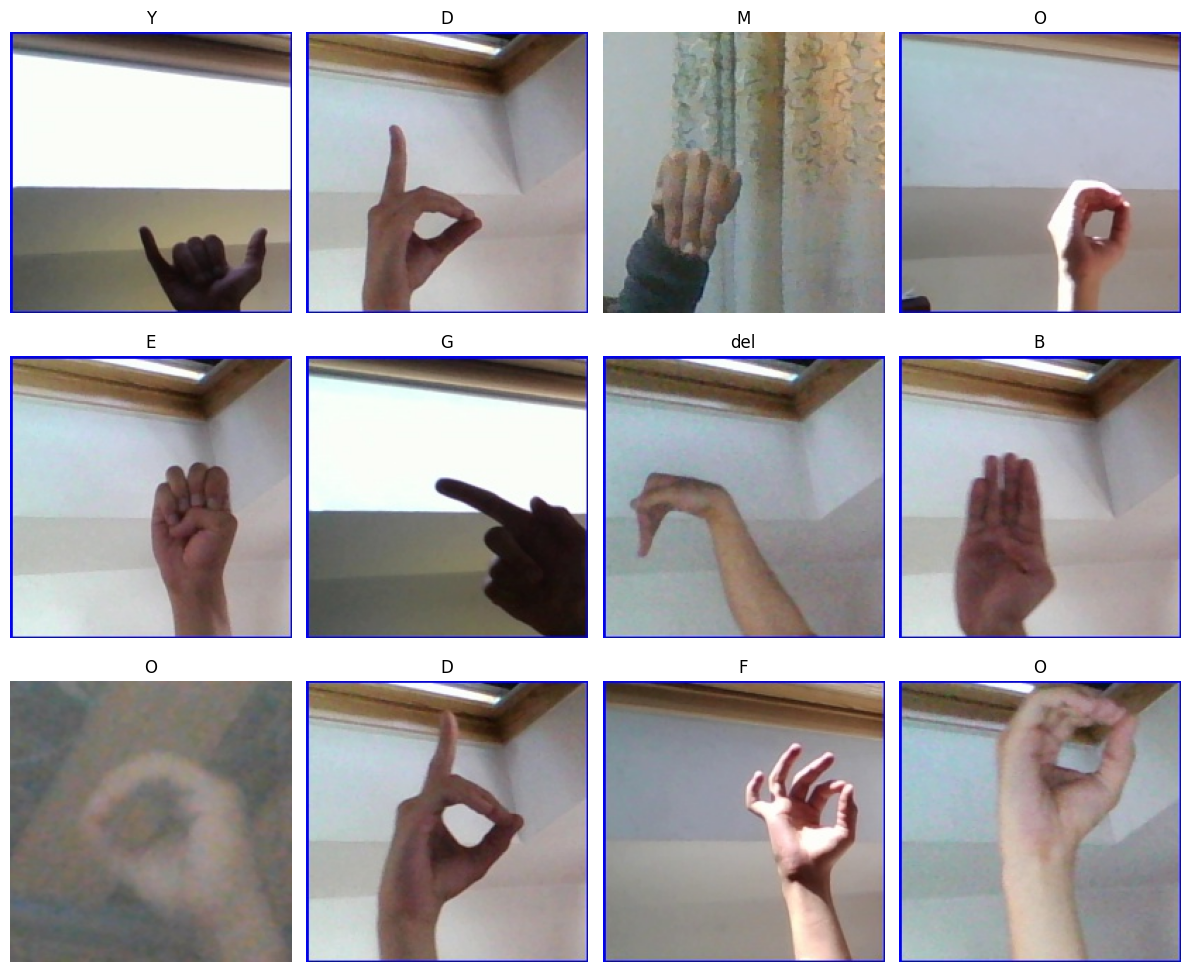

In [11]:
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

samples = random.sample(
    image_files,
    min(12, len(image_files))
)

fig, axes = plt.subplots(3, 4, figsize=(12, 10))

for ax, image_path in zip(axes.flat, samples):

    img = Image.open(image_path).convert("RGB")

    ax.imshow(img)
    ax.set_title(image_path.parent.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
from pathlib import Path

DATASET_ROOT = Path(path) / "ASL_Alphabet_Dataset"

TRAIN_DIR = DATASET_ROOT / "asl_alphabet_train"
TEST_DIR = DATASET_ROOT / "asl_alphabet_test"

print("Training directory exists:", TRAIN_DIR.exists())
print("Test directory exists:", TEST_DIR.exists())

Training directory exists: True
Test directory exists: True


In [13]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

class_names = sorted(
    folder.name
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
)

class_counts = {}

for class_name in class_names:

    folder = TRAIN_DIR / class_name

    images = [
        p for p in folder.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    class_counts[class_name] = len(images)

print("Number of classes:", len(class_names))
print("Total training images:", sum(class_counts.values()))
print("Classes:", class_names)

Number of classes: 29
Total training images: 223074
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


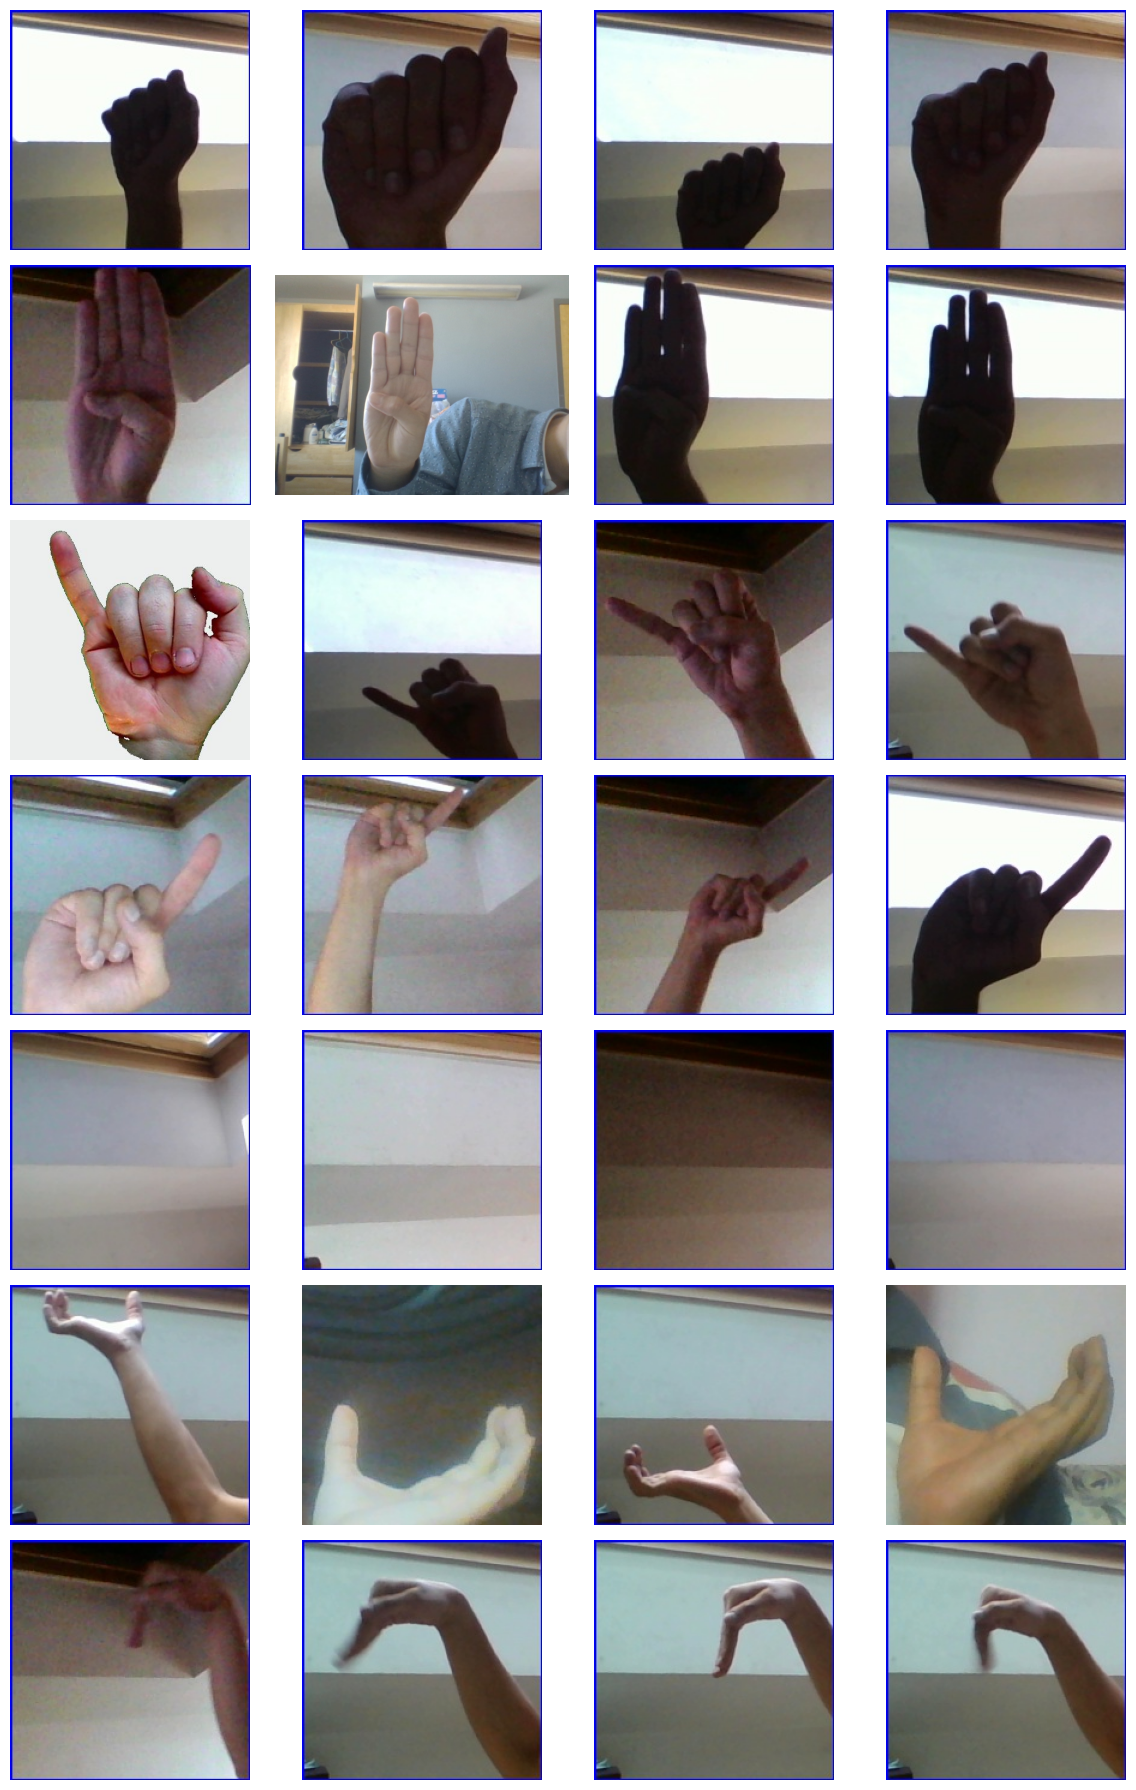

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
import random

selected_classes = ["A", "B", "J", "Z", "nothing", "space", "del"]

fig, axes = plt.subplots(
    len(selected_classes),
    4,
    figsize=(12, 18)
)

for row, class_name in enumerate(selected_classes):

    image_paths = list(
        (TRAIN_DIR / class_name).glob("*")
    )

    image_paths = [
        p for p in image_paths
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    samples = random.sample(image_paths, min(4, len(image_paths)))

    for col, image_path in enumerate(samples):

        img = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                class_name,
                fontsize=12
            )

plt.tight_layout()
plt.show()

In [15]:
from collections import Counter

dimensions = Counter()

for class_name in class_names:

    for image_path in (TRAIN_DIR / class_name).iterdir():

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(image_path) as img:
                dimensions[img.size] += 1
        except Exception:
            pass

print("Most common image dimensions:")

for size, count in dimensions.most_common(10):
    print(size, ":", count)

Most common image dimensions:
(200, 200) : 196478
(400, 400) : 18150
(640, 480) : 6680
(1920, 1920) : 1561
(1280, 720) : 201
(150, 200) : 4


**Mediapipe**

In [16]:
!pip install -q mediapipe

In [17]:
import mediapipe as mp
import cv2
import numpy as np
import matplotlib.pyplot as plt

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)

MediaPipe: 1.2.2
OpenCV: 5.0.0


In [18]:
!wget -q -O hand_landmarker.task \
https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task

In [19]:
BaseOptions = python.BaseOptions
HandLandmarker = vision.HandLandmarker
HandLandmarkerOptions = vision.HandLandmarkerOptions
RunningMode = vision.RunningMode

options = HandLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path="hand_landmarker.task"
    ),
    running_mode=RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5
)

landmarker = HandLandmarker.create_from_options(options)

print("Hand Landmarker initialized successfully!")

Hand Landmarker initialized successfully!


In [20]:
import random
from PIL import Image

sample_path = random.choice(
    list((TRAIN_DIR / "A").glob("*.jpg"))
)

image = cv2.imread(str(sample_path))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

result = landmarker.detect(mp_image)

print("Image:", sample_path.name)
print("Detected hands:", len(result.hand_landmarks))

Image: 372.jpg
Detected hands: 1


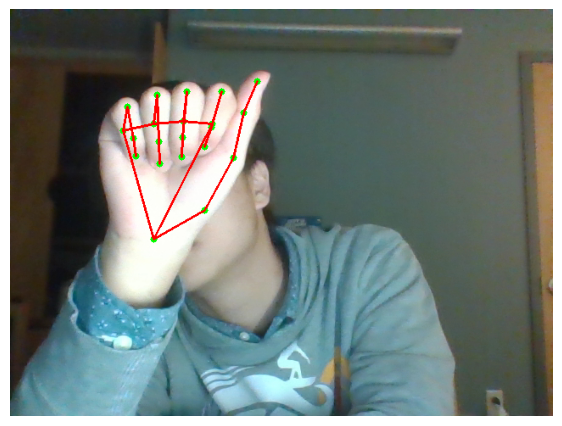

In [21]:
annotated_image = image_rgb.copy()

height, width, _ = annotated_image.shape

connections = (
    vision.HandLandmarksConnections.HAND_CONNECTIONS
)

if result.hand_landmarks:

    for hand_landmarks in result.hand_landmarks:

        points = []

        for landmark in hand_landmarks:

            x = int(landmark.x * width)
            y = int(landmark.y * height)

            points.append((x, y))

            cv2.circle(
                annotated_image,
                (x, y),
                4,
                (0, 255, 0),
                -1
            )

        for connection in connections:

            cv2.line(
                annotated_image,
                points[connection.start],
                points[connection.end],
                (255, 0, 0),
                2
            )

plt.figure(figsize=(7, 7))
plt.imshow(annotated_image)
plt.axis("off")
plt.show()

In [22]:
landmarks = result.hand_landmarks[0]

landmark_data = []

for i, point in enumerate(landmarks):

    landmark_data.append({
        "landmark_id": i,
        "x": point.x,
        "y": point.y,
        "z": point.z
    })

import pandas as pd

landmark_df = pd.DataFrame(landmark_data)

display(landmark_df)

,landmark_id,x,y,z
0,0,0.264814,0.565167,-3.449146e-07
1,1,0.358774,0.494589,-2.098994e-02
2,2,0.412229,0.365267,-2.327962e-02
3,3,0.430916,0.254594,-2.799065e-02
4,4,0.456163,0.177738,-2.517770e-02
5,5,0.372823,0.282985,1.410463e-02
6,6,0.389064,0.202884,-2.619178e-02
7,7,0.371850,0.290934,-4.418731e-02
8,8,0.358353,0.339119,-4.761693e-02
9,9,0.318933,0.276350,1.104943e-02


In [23]:
import random
from tqdm.notebook import tqdm

SAMPLES_PER_CLASS = 100

detection_results = []

for class_name in class_names:

    folder = TRAIN_DIR / class_name

    images = [
        p for p in folder.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    samples = random.sample(
        images,
        min(SAMPLES_PER_CLASS, len(images))
    )

    zero_hands = 0
    one_hand = 0
    two_hands = 0

    for image_path in samples:

        image = cv2.imread(str(image_path))

        if image is None:
            continue

        image_rgb = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=image_rgb
        )

        output = landmarker.detect(mp_image)

        count = len(output.hand_landmarks)

        if count == 0:
            zero_hands += 1
        elif count == 1:
            one_hand += 1
        else:
            two_hands += 1

    total = zero_hands + one_hand + two_hands

    detection_results.append({
        "Class": class_name,
        "Tested": total,
        "Zero Hands": zero_hands,
        "One Hand": one_hand,
        "Two Hands": two_hands,
        "Detection Rate (%)": round(
            (one_hand + two_hands) / total * 100, 2
        ) if total else 0
    })

detection_df = pd.DataFrame(detection_results)

display(detection_df)

,Class,Tested,Zero Hands,One Hand,Two Hands,Detection Rate (%)
0,A,100,32,68,0,68.0
1,B,100,27,73,0,73.0
2,C,100,43,56,1,57.0
3,D,100,22,78,0,78.0
4,E,100,37,63,0,63.0
5,F,100,6,94,0,94.0
6,G,100,22,78,0,78.0
7,H,100,27,72,1,73.0
8,I,100,30,70,0,70.0
9,J,100,33,67,0,67.0


In [24]:
import numpy as np
import cv2
from tqdm.notebook import tqdm

class_name = "A"
class_folder = TRAIN_DIR / class_name

image_paths = [
    p for p in class_folder.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

accepted_features = []
accepted_paths = []

zero_hand_count = 0
multiple_hand_count = 0

for image_path in tqdm(image_paths[:100]):

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    output = landmarker.detect(mp_image)

    # Keep only images with exactly one detected hand
    if len(output.hand_landmarks) == 1:

        hand = output.hand_landmarks[0]

        features = []

        for point in hand:
            features.extend([point.x, point.y, point.z])

        accepted_features.append(features)
        accepted_paths.append(str(image_path))

    elif len(output.hand_landmarks) == 0:
        zero_hand_count += 1

    else:
        multiple_hand_count += 1

print("Accepted:", len(accepted_features))
print("Zero hands:", zero_hand_count)
print("Multiple hands:", multiple_hand_count)

print("Feature shape:", np.array(accepted_features).shape)

  0%|          | 0/100 [00:00<?, ?it/s]

Accepted: 58
Zero hands: 42
Multiple hands: 0
Feature shape: (58, 63)


In [25]:
OUTPUT_DIR = ARTIFACTS_DIR / "filtered_landmarks"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

alphabet_classes = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

summary = []

for class_name in alphabet_classes:

    print(f"\nProcessing class: {class_name}")

    class_folder = TRAIN_DIR / class_name

    image_paths = [
        p for p in class_folder.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    features_list = []
    paths_list = []

    zero_hands = 0
    multiple_hands = 0
    unreadable = 0

    for image_path in tqdm(image_paths):

        image = cv2.imread(str(image_path))

        if image is None:
            unreadable += 1
            continue

        image_rgb = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=image_rgb
        )

        output = landmarker.detect(mp_image)

        if len(output.hand_landmarks) == 1:

            hand = output.hand_landmarks[0]

            features = []

            for point in hand:
                features.extend([
                    point.x,
                    point.y,
                    point.z
                ])

            features_list.append(features)
            paths_list.append(str(image_path))

        elif len(output.hand_landmarks) == 0:
            zero_hands += 1

        else:
            multiple_hands += 1

    features_array = np.asarray(
        features_list,
        dtype=np.float32
    ).reshape(-1, 63)

    # Save each class separately
    np.savez_compressed(
        OUTPUT_DIR / f"{class_name}.npz",
        X=features_array,
        y=np.full(len(features_array), class_name),
        paths=np.asarray(paths_list)
    )

    total = len(image_paths)
    accepted = len(features_list)

    summary.append({
        "Class": class_name,
        "Original": total,
        "Accepted": accepted,
        "Zero Hands": zero_hands,
        "Multiple Hands": multiple_hands,
        "Unreadable": unreadable,
        "Acceptance Rate (%)": round(
            accepted / total * 100, 2
        ) if total else 0
    })

    print(
        f"Accepted {accepted}/{total} "
        f"({accepted / total * 100:.2f}%)"
    )

    # Save progress after every class
    pd.DataFrame(summary).to_csv(
        OUTPUT_DIR / "filtering_summary.csv",
        index=False
    )


Processing class: A


  0%|          | 0/8458 [00:00<?, ?it/s]

Accepted 5266/8458 (62.26%)

Processing class: B


  0%|          | 0/8309 [00:00<?, ?it/s]

Accepted 5993/8309 (72.13%)

Processing class: C


  0%|          | 0/8146 [00:00<?, ?it/s]

... (43 outputs left out)

  0%|          | 0/8178 [00:00<?, ?it/s]

Accepted 5946/8178 (72.71%)

Processing class: Z


  0%|          | 0/7410 [00:00<?, ?it/s]

Accepted 5393/7410 (72.78%)


In [26]:
for class_name in alphabet_classes:

    file_path = OUTPUT_DIR / f"{class_name}.npz"

    if file_path.exists():

        data = np.load(file_path)

        print(
            class_name,
            "X:", data["X"].shape,
            "y:", data["y"].shape
        )

    else:
        print(class_name, "MISSING!")

A X: (5266, 63) y: (5266,)
B X: (5993, 63) y: (5993,)
C X: (4697, 63) y: (4697,)
D X: (5962, 63) y: (5962,)
E X: (5407, 63) y: (5407,)
F X: (7438, 63) y: (7438,)
G X: (6011, 63) y: (6011,)
H X: (5820, 63) y: (5820,)
I X: (5698, 63) y: (5698,)
J X: (5554, 63) y: (5554,)
K X: (6707, 63) y: (6707,)
L X: (6565, 63) y: (6565,)
M X: (3753, 63) y: (3753,)
N X: (3017, 63) y: (3017,)
O X: (5281, 63) y: (5281,)
P X: (4685, 63) y: (4685,)
Q X: (4915, 63) y: (4915,)
R X: (6057, 63) y: (6057,)
S X: (5695, 63) y: (5695,)
T X: (5462, 63) y: (5462,)
U X: (6025, 63) y: (6025,)
V X: (6123, 63) y: (6123,)
W X: (6043, 63) y: (6043,)
X X: (5311, 63) y: (5311,)
Y X: (5946, 63) y: (5946,)
Z X: (5393, 63) y: (5393,)


In [27]:
summary_df = pd.read_csv(
    OUTPUT_DIR / "filtering_summary.csv"
)

display(summary_df)

print("Total accepted:", summary_df["Accepted"].sum())

,Class,Original,Accepted,Zero Hands,Multiple Hands,Unreadable,Acceptance Rate (%)
0,A,8458,5266,3192,0,0,62.26
1,B,8309,5993,2314,2,0,72.13
2,C,8146,4697,3342,107,0,57.66
3,D,7629,5962,1664,3,0,78.15
4,E,7744,5407,2330,7,0,69.82
5,F,8031,7438,564,29,0,92.62
6,G,7844,6011,1825,8,0,76.63
7,H,7906,5820,2053,33,0,73.61
8,I,7953,5698,2250,5,0,71.65
9,J,7503,5554,1949,0,0,74.02


Total accepted: 144824


In [28]:
import numpy as np
import pandas as pd

X_list = []
y_list = []
paths_list = []

for class_name in alphabet_classes:

    data = np.load(OUTPUT_DIR / f"{class_name}.npz")

    X_list.append(data["X"])
    y_list.append(data["y"])
    paths_list.append(data["paths"])

X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)
image_paths = np.concatenate(paths_list, axis=0)

print("Feature matrix:", X.shape)
print("Labels:", y.shape)
print("Image paths:", image_paths.shape)


Feature matrix: (144824, 63)
Labels: (144824,)
Image paths: (144824,)


In [29]:
sample_index = 0

sample = X[sample_index]

print("Class:", y[sample_index])
print("Features:", sample.shape)
print(sample)

Class: A
Features: (63,)
[ 2.71253198e-01  5.54894745e-01  4.91527068e-08  3.86845350e-01
  4.87634957e-01 -2.31821146e-02  4.50905949e-01  3.69043499e-01
 -2.99224127e-02  4.53953654e-01  2.64149517e-01 -4.13781740e-02
  4.43442583e-01  1.88511267e-01 -5.01122661e-02  3.89047891e-01
  2.97560453e-01  4.17018123e-03  3.84387672e-01  2.16620371e-01
 -5.43559827e-02  3.85804027e-01  2.79989541e-01 -9.19203833e-02
  3.95731688e-01  3.47549021e-01 -1.07248113e-01  3.13518792e-01
  3.06533515e-01 -6.92193396e-03  3.22238386e-01  2.44967282e-01
 -7.62719959e-02  3.31168443e-01  3.39242548e-01 -1.03974946e-01
  3.37734967e-01  4.16425288e-01 -1.06373295e-01  2.42449313e-01
  3.25356662e-01 -2.61148177e-02  2.57067084e-01  2.75542259e-01
 -9.97874737e-02  2.70079434e-01  3.76002461e-01 -9.97331142e-02
  2.78003693e-01  4.48761344e-01 -7.86401704e-02  1.70332432e-01
  3.53525370e-01 -4.65008095e-02  1.89506143e-01  3.23994100e-01
 -9.96535644e-02  2.09685534e-01  3.95265043e-01 -9.72227827e-02


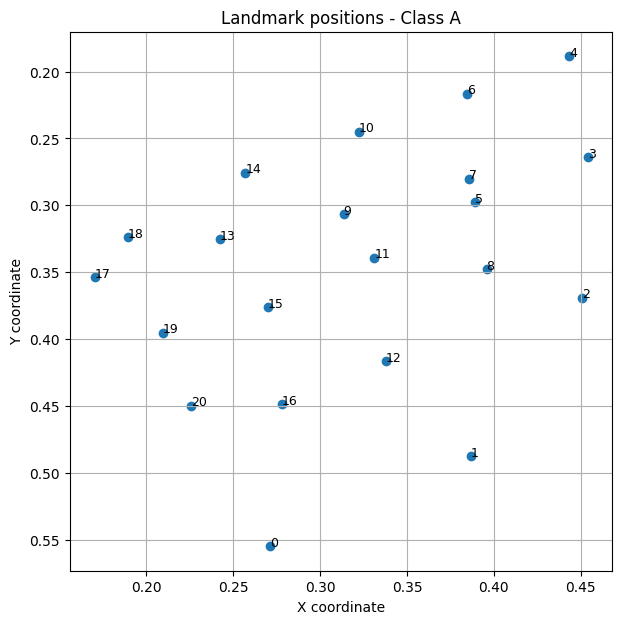

In [30]:
sample_landmarks = X[0].reshape(21, 3)

plt.figure(figsize=(7, 7))

plt.scatter(
    sample_landmarks[:, 0],
    sample_landmarks[:, 1]
)

for i, (x, y_coord, z) in enumerate(sample_landmarks):
    plt.text(x, y_coord, str(i), fontsize=9)

plt.gca().invert_yaxis()
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title(f"Landmark positions - Class {y[0]}")
plt.grid()
plt.show()

In [31]:
print("Minimum:", X.min())
print("Maximum:", X.max())
print("Mean:", X.mean())
print("Standard deviation:", X.std())

print("\nNaN values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())

Minimum: -1.1897436
Maximum: 1.3289
Mean: 0.31261912
Standard deviation: 0.31516048

NaN values: 0
Infinite values: 0


In [32]:
import numpy as np

def normalize_landmarks(features):

    landmarks = np.asarray(
        features, dtype=np.float32
    ).reshape(21, 3)

    # Wrist becomes the origin
    wrist = landmarks[0].copy()

    relative_landmarks = landmarks - wrist

    # Calculate distance of every landmark from wrist
    distances = np.linalg.norm(
        relative_landmarks,
        axis=1
    )

    # Use maximum distance as hand scale
    scale = distances.max()

    if scale < 1e-6:
        raise ValueError("Invalid hand landmark scale")

    normalized = relative_landmarks / scale

    return normalized.flatten()

In [33]:
sample_raw = X[0]

sample_normalized = normalize_landmarks(sample_raw)

print("Original shape:", sample_raw.shape)
print("Normalized shape:", sample_normalized.shape)

print("\nOriginal:")
print(sample_raw)

print("\nNormalized:")
print(sample_normalized)

Original shape: (63,)
Normalized shape: (63,)

Original:
[ 2.71253198e-01  5.54894745e-01  4.91527068e-08  3.86845350e-01
  4.87634957e-01 -2.31821146e-02  4.50905949e-01  3.69043499e-01
 -2.99224127e-02  4.53953654e-01  2.64149517e-01 -4.13781740e-02
  4.43442583e-01  1.88511267e-01 -5.01122661e-02  3.89047891e-01
  2.97560453e-01  4.17018123e-03  3.84387672e-01  2.16620371e-01
 -5.43559827e-02  3.85804027e-01  2.79989541e-01 -9.19203833e-02
  3.95731688e-01  3.47549021e-01 -1.07248113e-01  3.13518792e-01
  3.06533515e-01 -6.92193396e-03  3.22238386e-01  2.44967282e-01
 -7.62719959e-02  3.31168443e-01  3.39242548e-01 -1.03974946e-01
  3.37734967e-01  4.16425288e-01 -1.06373295e-01  2.42449313e-01
  3.25356662e-01 -2.61148177e-02  2.57067084e-01  2.75542259e-01
 -9.97874737e-02  2.70079434e-01  3.76002461e-01 -9.97331142e-02
  2.78003693e-01  4.48761344e-01 -7.86401704e-02  1.70332432e-01
  3.53525370e-01 -4.65008095e-02  1.89506143e-01  3.23994100e-01
 -9.96535644e-02  2.09685534e-01 

In [34]:
print(
    "Normalized wrist:",
    sample_normalized.reshape(21, 3)[0]
)

Normalized wrist: [0. 0. 0.]


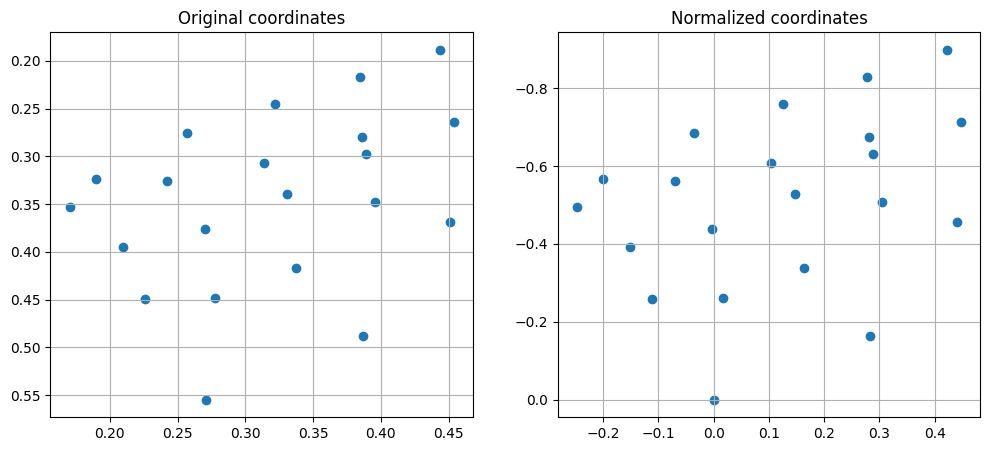

In [35]:
raw_landmarks = X[0].reshape(21, 3)
norm_landmarks = sample_normalized.reshape(21, 3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(raw_landmarks[:, 0], raw_landmarks[:, 1])

axes[0].set_title("Original coordinates")
axes[0].invert_yaxis()
axes[0].grid()

axes[1].scatter(norm_landmarks[:, 0], norm_landmarks[:, 1])

axes[1].set_title("Normalized coordinates")
axes[1].invert_yaxis()
axes[1].grid()

plt.show()

In [36]:
normalized_sample = sample_normalized.reshape(21, 3)

distances = np.linalg.norm(
    normalized_sample,
    axis=1
)

print("Wrist distance:", distances[0])
print("Maximum distance:", distances.max())
print("Minimum distance:", distances.min())

Wrist distance: 0.0
Maximum distance: 1.0
Minimum distance: 0.0


In [37]:
X_normalized = np.array(
    [normalize_landmarks(sample) for sample in X],
    dtype=np.float32
)

print("Original shape:", X.shape)
print("Normalized shape:", X_normalized.shape)

Original shape: (144824, 63)
Normalized shape: (144824, 63)


In [38]:
print("NaN:", np.isnan(X_normalized).sum())
print("Inf:", np.isinf(X_normalized).sum())

print("Minimum:", X_normalized.min())
print("Maximum:", X_normalized.max())

NaN: 0
Inf: 0
Minimum: -0.99998695
Maximum: 0.99972874


In [39]:
PROCESSED_DIR = ARTIFACTS_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    PROCESSED_DIR / "asl_normalized.npz",
    X=X_normalized,
    y=y,
    paths=image_paths
)

print("Normalized dataset saved!")

Normalized dataset saved!


DATASET SPLITTING PHASE

In [40]:
data = np.load(PROCESSED_DIR / "asl_normalized.npz")

X = data["X"]
y = data["y"]
image_paths = data["paths"]

print("X:", X.shape)
print("y:", y.shape)

X: (144824, 63)
y: (144824,)


In [41]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Encoded labels:", np.unique(y_encoded))

Classes: ['A' 'B' 'C' 'D' 'E' 'F' 'G' 'H' 'I' 'J' 'K' 'L' 'M' 'N' 'O' 'P' 'Q' 'R'
 'S' 'T' 'U' 'V' 'W' 'X' 'Y' 'Z']
Encoded labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25]


In [42]:
import joblib

joblib.dump(
    label_encoder,
    PROCESSED_DIR / "label_encoder.joblib"
)

['/content/drive/MyDrive/ASL-Recognition/artifacts/processed/label_encoder.joblib']

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (101376, 63) (101376,)
Validation: (21724, 63) (21724,)
Testing: (21724, 63) (21724,)


In [44]:
import pandas as pd

distribution = pd.DataFrame({
    "Class": label_encoder.classes_,
    "Train": np.bincount(y_train, minlength=26),
    "Validation": np.bincount(y_val, minlength=26),
    "Test": np.bincount(y_test, minlength=26)
})

display(distribution)

,Class,Train,Validation,Test
0,A,3686,790,790
1,B,4195,899,899
2,C,3288,704,705
3,D,4173,895,894
4,E,3785,811,811
5,F,5207,1116,1115
6,G,4208,901,902
7,H,4074,873,873
8,I,3989,854,855
9,J,3888,833,833


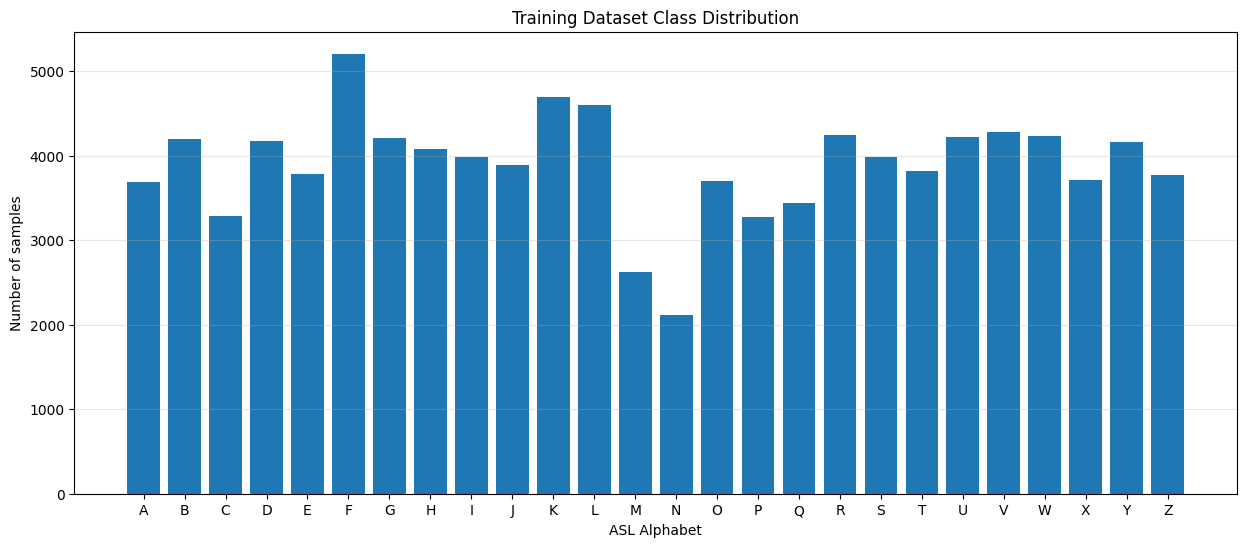

In [45]:
plt.figure(figsize=(15, 6))

plt.bar(
    distribution["Class"],
    distribution["Train"]
)

plt.xlabel("ASL Alphabet")
plt.ylabel("Number of samples")
plt.title("Training Dataset Class Distribution")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [46]:
np.savez_compressed(
    PROCESSED_DIR / "asl_splits.npz",
    X_train=X_train,
    X_val=X_val,
    X_test=X_test,
    y_train=y_train,
    y_val=y_val,
    y_test=y_test
)

print("Dataset splits saved successfully!")

Dataset splits saved successfully!


**ANALYSE CLAsS IMBALANCE**

In [47]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

for class_id, weight in class_weights.items():
    class_name = label_encoder.inverse_transform([class_id])[0]
    print(f"{class_name}: {weight:.4f}")

A: 1.0578
B: 0.9295
C: 1.1859
D: 0.9344
E: 1.0301
F: 0.7488
G: 0.9266
H: 0.9571
I: 0.9775
J: 1.0028
K: 0.8305
L: 0.8485
M: 1.4842
N: 1.8462
O: 1.0547
P: 1.1887
Q: 1.1335
R: 0.9196
S: 0.9782
T: 1.0199
U: 0.9246
V: 0.9097
W: 0.9218
X: 1.0487
Y: 0.9368
Z: 1.0329


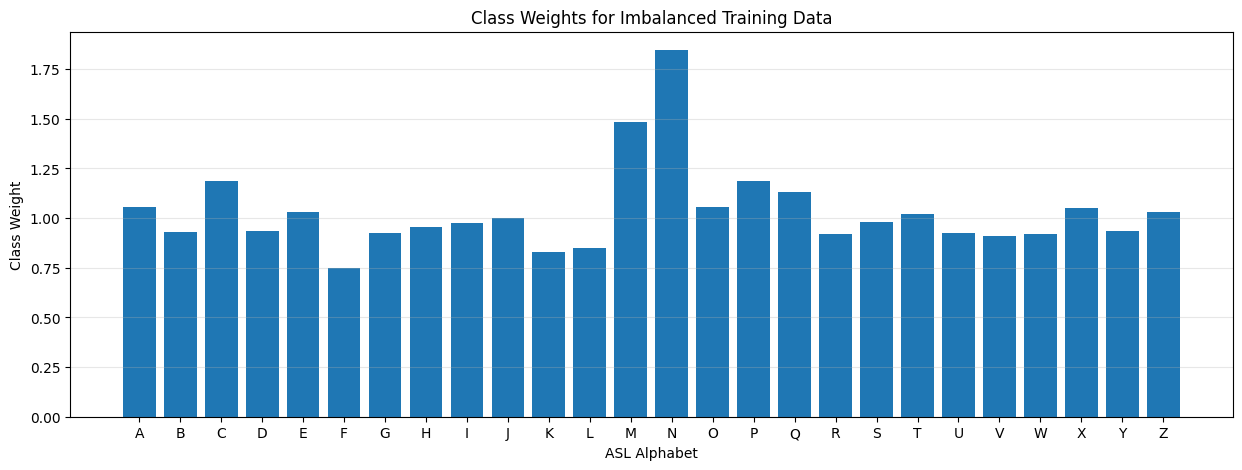

In [48]:
weight_df = pd.DataFrame({
    "Class": label_encoder.classes_,
    "Weight": [class_weights[i] for i in range(26)]
})

plt.figure(figsize=(15, 5))

plt.bar(weight_df["Class"], weight_df["Weight"])

plt.xlabel("ASL Alphabet")
plt.ylabel("Class Weight")
plt.title("Class Weights for Imbalanced Training Data")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [49]:
import json

with open(PROCESSED_DIR / "class_weights.json", "w") as f:
    json.dump(class_weights, f, indent=4)

***BUILDING CLASSIFIER***

In [50]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [51]:
model = Sequential([
    tf.keras.Input(shape=(63,)),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    Dense(26, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 26)             │         1,690 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,906 (73.85 KB)

 Trainable params: 18,522 (72.35 KB)

 Non-trainable params: 384 (1.50 KB)

In [52]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [53]:
callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        str(MODELS_DIR / "best_asl_mlp.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )
]

In [54]:
history = model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=100,
    batch_size=256,

    class_weight=class_weights,

    callbacks=callbacks,
    verbose=1
)

Epoch 1/100
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6449 - loss: 1.3712
Epoch 1: val_loss improved from None to 0.70065, saving model to /content/drive/MyDrive/ASL-Recognition/models/best_asl_mlp.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ASL-Recognition/models/best_asl_mlp.keras
396/396 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7957 - loss: 0.7935 - val_accuracy: 0.8869 - val_loss: 0.7007 - learning_rate: 0.0010
Epoch 2/100
394/396 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9154 - loss: 0.3316
Epoch 2: val_loss improved from 0.70065 to 0.17124, saving model to /content/drive/MyDrive/ASL-Recognition/models/best_asl_mlp.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ASL-Recognition/models/best_asl_mlp.keras
396/396 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9216 - loss: 0.3063 - val_accuracy: 0.9533 - val_loss: 0.1712 - learning_rate: 0.0010
Epoch 3/100
393/396 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9353 - loss:

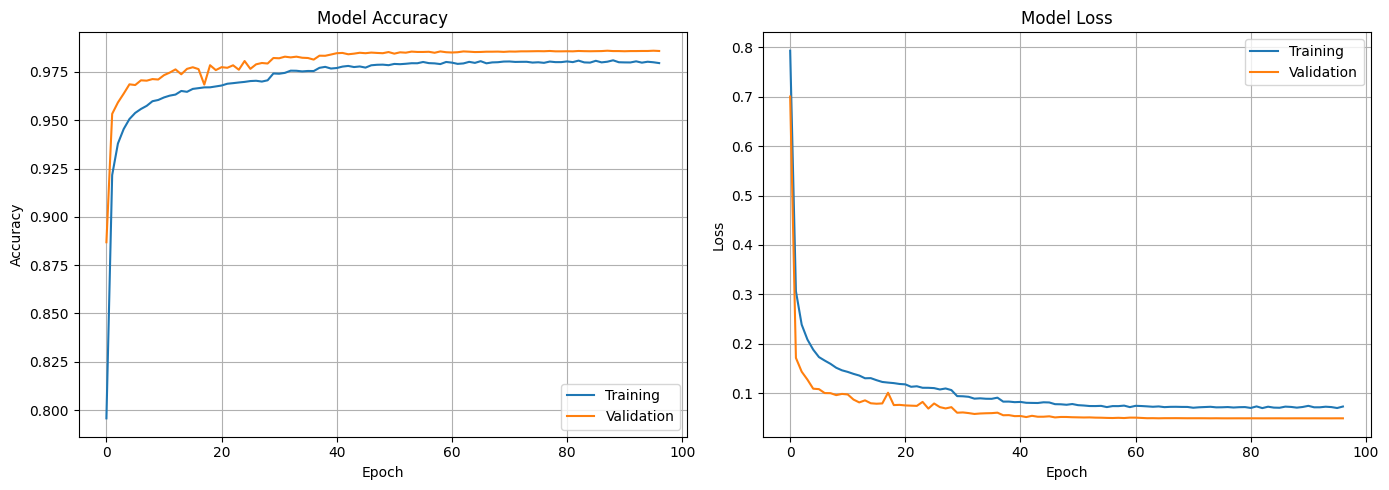

In [55]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [56]:
best_model = tf.keras.models.load_model(
    MODELS_DIR / "best_asl_mlp.keras"
)

In [57]:
test_loss, test_accuracy = best_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

679/679 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9878 - loss: 0.0447
Test Loss: 0.0447
Test Accuracy: 98.78%


In [58]:
y_prob = best_model.predict(X_test)

y_pred = np.argmax(y_prob, axis=1)

print("Predictions:", y_pred[:20])
print("Actual:     ", y_test[:20])

679/679 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
Predictions: [ 7 23  1  0 15 13 25 13 20 23 10  0 20 18 14  5  8 20 15 13]
Actual:      [ 7 23  1  0 15 13 25 13 20 23 10  0 20 18 14  5  8 20 15 13]


In [59]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_,
        digits=4
    )
)

              precision    recall  f1-score   support

           A     0.9887    0.9949    0.9918       790
           B     0.9967    1.0000    0.9983       899
           C     0.9901    0.9915    0.9908       705
           D     0.9944    0.9944    0.9944       894
           E     0.9863    0.9766    0.9814       811
           F     0.9991    0.9955    0.9973      1115
           G     0.9945    0.9933    0.9939       902
           H     0.9829    0.9885    0.9857       873
           I     0.9894    0.9789    0.9841       855
           J     0.9904    0.9880    0.9892       833
           K     0.9920    0.9911    0.9915      1006
           L     1.0000    0.9980    0.9990       985
           M     0.9432    0.9734    0.9580       563
           N     0.9662    0.9491    0.9576       452
           O     0.9789    0.9949    0.9869       792
           P     0.9986    0.9915    0.9950       703
           Q     0.9839    0.9919    0.9879       738
           R     0.9813    

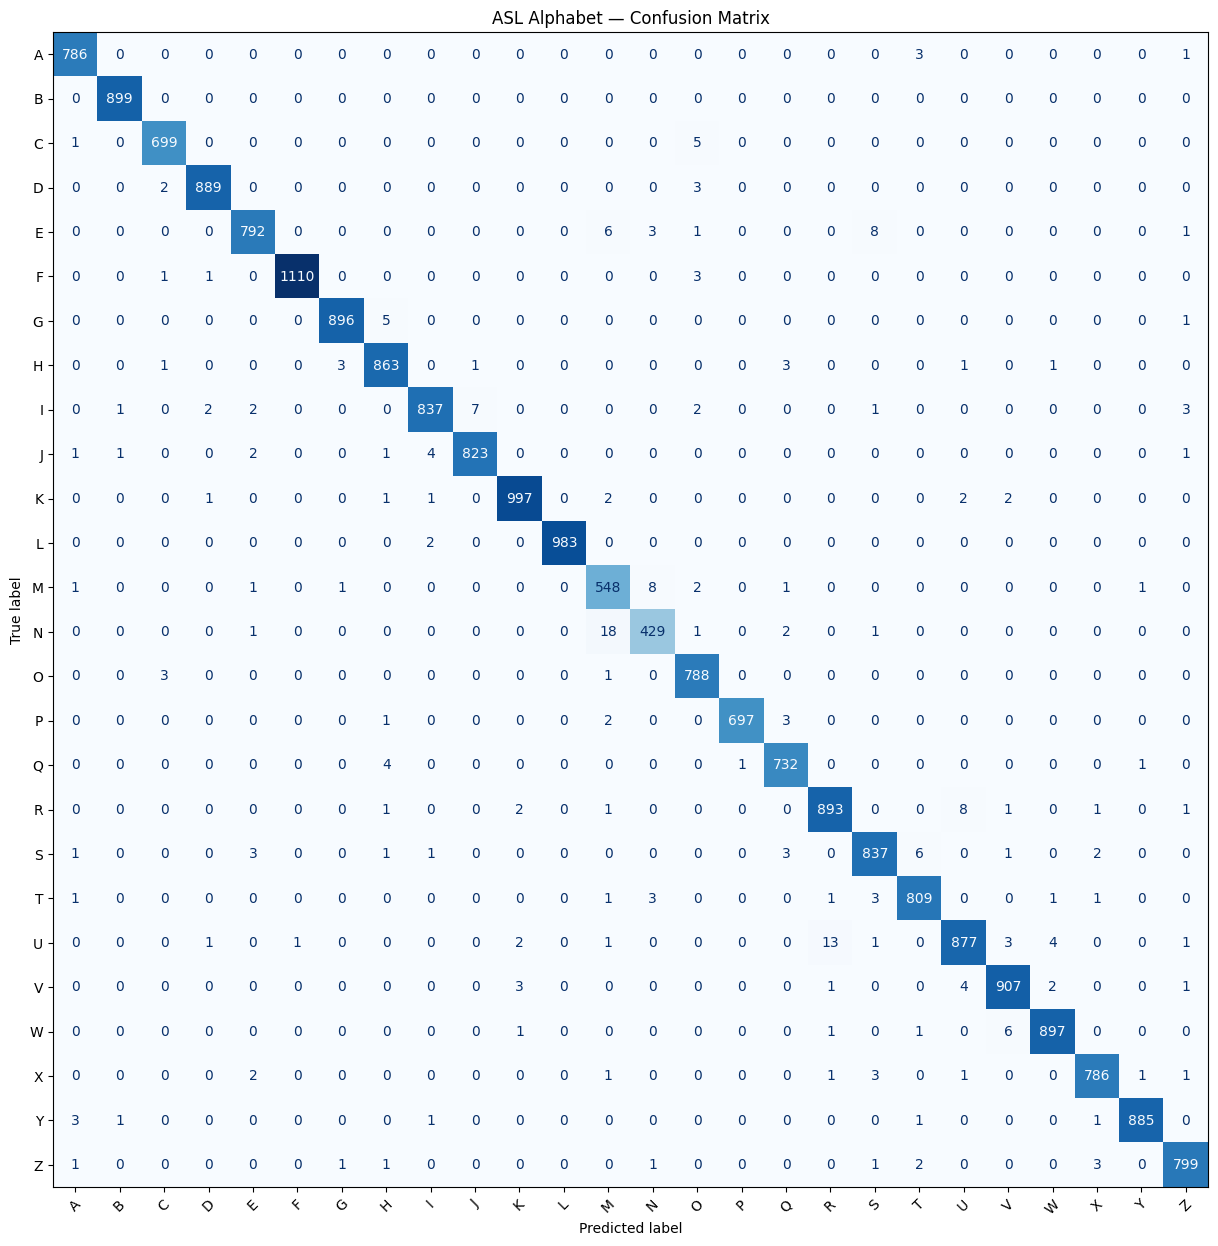

In [60]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(15, 15))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    ax=plt.gca(),
    colorbar=False
)

plt.title("ASL Alphabet — Confusion Matrix")
plt.show()

###ANALYSE MISCLASSIFIED IMAGES

In [61]:
incorrect_indices = np.where(y_pred != y_test)[0]

print("Incorrect predictions:", len(incorrect_indices))

error_analysis = pd.DataFrame({
    "Actual": label_encoder.inverse_transform(
        y_test[incorrect_indices]
    ),
    "Predicted": label_encoder.inverse_transform(
        y_pred[incorrect_indices]
    ),
    "Confidence": np.max(
        y_prob[incorrect_indices],
        axis=1
    )
})

display(error_analysis.head(30))

Incorrect predictions: 266


,Actual,Predicted,Confidence
0,U,D,0.762671
1,W,V,0.522564
2,H,W,0.187463
3,T,A,0.898229
4,M,N,0.693554
5,X,S,0.662979
6,F,O,0.631733
7,N,M,0.892516
8,N,S,0.116153
9,S,I,0.418516


In [62]:
confusion_pairs = (
    error_analysis
    .groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

display(confusion_pairs.head(20))

,Actual,Predicted,Count
50,N,M,18
88,U,R,13
45,M,N,8
65,R,U,8
9,E,S,8
25,I,J,7
74,S,T,6
101,W,V,6
6,E,M,6
14,G,H,5


In [63]:
import os
import json
import joblib
import shutil

# Project directories
PROJECT_DIR = "/content/drive/MyDrive/ASL-Recognition"
MODELS_DIR = os.path.join(PROJECT_DIR, "models")

os.makedirs(MODELS_DIR, exist_ok=True)

# 1. Load the best trained model
best_model = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, "best_asl_mlp.keras")
)

# 2. Save a separate baseline copy
best_model.save(
    os.path.join(MODELS_DIR, "asl_mlp_baseline.keras")
)

# 3. Save the label encoder
joblib.dump(
    label_encoder,
    os.path.join(MODELS_DIR, "label_encoder.joblib")
)

# 4. Save the class names as JSON
class_names = label_encoder.classes_.tolist()

with open(os.path.join(MODELS_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=4)

print("Model and supporting files saved successfully!")
print("Classes:", class_names)

Model and supporting files saved successfully!
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
